# Quantifying Parameter Uncertainty in a Large-Scale Glacier Evolution Model Using Bayesian Inference: Application to High Mountain Asia

__David R. Rounce__, Geophysical Institute, University of Alaska Fairbanks, Fairbanks, AK, USA

__Tushar Khurana__, Geophysical Institute, University of Alaska Fairbanks, Fairbanks, AK, USA, and Department of Civil and Environmental Engineering, University of Washington, Seattle, WA, USA

__Margaret B. Short__, College of Natural Science and Mathematics, University of Alaska Fairbanks, Fairbanks, AK, USA

__Regine Hock__, Geophysical Institute, University of Alaska Fairbanks, Fairbanks, AK, USA

__David E. Shean__, Department of Civil and Environmental Engineering, University of Washington, Seattle, WA, USA

__Douglas J. Brinkerhoff__, Department of Computer Science, University of Montana, Missoula, MT, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

> **Not the paper's glacier or forcing.** The paper [[1]][R1] calibrates every glacier of High Mountain Asia with ERA-Interim forcing and RGI v6.0 geometry. Neither the ERA-Interim series nor the High Mountain Asia geometry could be obtained for this data set, so it runs the paper's model on **Hintereisferner (RGI60-11.00897, Ötztal Alps, Austria)** with **ERA5** monthly forcing for 2000–2017, both taken from the OGGM sample-data repository [[6]][R6]. The model equations, options and calibrated parameters are the paper's; the numbers are this glacier's.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import pygem_mb_model as pm
from generate_data import BOX, SEEDS

SEED = 601                        # the only seed of the analysis (bootstrap, posterior sketch); also the m3 data seed
t_start = time.perf_counter()
sym = {'k_p': r'$k_p$', 'T_bias': r'$T_{\mathrm{bias}}$', 'f_snow': r'$f_{\mathrm{snow}}$',
       'd_prec': r'$d_{\mathrm{prec}}$', 'T_snow': r'$T_{\mathrm{snow}}$'}
qlabel = r'$B$ (m w.e. a$^{-1}$)'


def order(v):
    """Order of magnitude of a rounding-level value; such values change between platforms."""
    return f'1e{int(np.floor(np.log10(abs(v))))}' if v != 0 else '0'


### Summary

Rounce et al. [[1]][R1] calibrate three parameters of the Python Glacier Evolution Model (PyGEM), the precipitation factor $k_p$, the temperature bias $T_{\mathrm{bias}}$ and the degree-day factor of snow $f_{\mathrm{snow}}$, against one geodetic mass balance per glacier, and show that the three are not identifiable from it: many combinations give the same glacier-wide mass balance (Sec. 3.4, p. 179). We port PyGEM v0.1.0's mass-balance and mass-redistribution code to numpy, reproduce PyGEM v0.1.0 itself to rounding (of order $10^{-15}$ m w.e. a$^{-1}$) at 12 points (`check_accuracy.py`), and compute complex-step gradients, the exact derivative of the branch the model takes, of the 2000–2017 mass balance $B$ of a substitute glacier, Hintereisferner with ERA5 forcing. Over a box this data set chose, containing the regional prior means of $k_p$ in PyGEM v0.1.0, $B$ has a one-dimensional active subspace ($\lambda_1/\lambda_2 = 29.6$, with 25.8 and 115.2 on a wider and a narrower box; a cubic in $y_1$ has leave-one-out $R^2 = 0.972$) whose direction, more $k_p$ against more $T_{\mathrm{bias}}$ and $f_{\mathrm{snow}}$, is the trade-off behind the paper's non-identifiability; freeing the precipitation gradient and the snow/rain threshold adds almost nothing.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by Monte Carlo from gradient samples, with bootstrap intervals for the eigenvalues and subspaces; see Constantine [[2]][R2].

### The model

PyGEM [[1]][R1] (Sec. 2, pp. 176–177) computes the monthly climatic mass balance $b_{\mathrm{clim}} = a + c + R$ (ablation, accumulation, refreeze; Eq. 1) on 10 m elevation bins and aggregates it to the glacier-wide specific mass balance $B = \sum_{\mathrm{bin}} b_{\mathrm{clim,bin}} S_{\mathrm{bin}}/S$ (Eq. 2). As printed:

- Ablation (Eq. 3): $a_{m,\mathrm{bin}} = f_{\mathrm{snow/ice/firn}}\,T_{m,\mathrm{bin}}\,n$ if $T_{m,\mathrm{bin}} \ge 0$, else 0, with $n$ the days in the month. In the code, snow melts first and the remaining degree-days melt firn or ice.
- Temperature (Eq. 4): $T_{m,\mathrm{bin}} = T_{m,\mathrm{GCM}} + lr_{m,\mathrm{GCM}}(z_{\mathrm{ref}} - z_{\mathrm{GCM}}) + lr_{m,\mathrm{glac}}(z_{\mathrm{bin}} - z_{\mathrm{ref}}) + T_{\mathrm{bias}}$, $z_{\mathrm{ref}}$ the glacier's median elevation.
- Accumulation (Eqs. 5–6): $c_{m,\mathrm{bin}} = \delta_{m,\mathrm{bin}} P_{m,\mathrm{bin}}$ with $\delta = 1$ for $T \le T_{\mathrm{snow}} - 1$, $0$ for $T \ge T_{\mathrm{snow}} + 1$, and printed as $0.5 + (T_{m,\mathrm{bin}} - T_{\mathrm{snow}})/2$ in between. **The printed middle branch has the wrong sign**: it would make the snow fraction rise with temperature and jump at both ends. PyGEM v0.1.0 uses $0.5 + (T - T_{\mathrm{snow}})/2$ as the *rain* fraction, so the snow fraction is $\delta = 0.5 - (T_{m,\mathrm{bin}} - T_{\mathrm{snow}})/2$; the port follows the code.
- Precipitation (Eq. 7): $P_{m,\mathrm{bin}} = P_{m,\mathrm{GCM}}\,k_p\,(1 + d_{\mathrm{prec}}(z_{\mathrm{bin}} - z_{\mathrm{ref}}))$. The code also reduces precipitation on the uppermost 25 % of the bins of a glacier with more than 1000 m of relief (Huss and Hock [[3]][R3]), which applies here (1230 m).
- Refreeze (Eq. 8): potential $R_{\mathrm{potential}} = -0.0069\,T_a + 0.000096$ (m w.e.) from the weighted annual mean temperature, reset every October; melt refreezes until the potential is exhausted, and refreeze cannot exceed the snow depth or be negative (pp. 176–177). PyGEM v0.1.0's code also lets rain refreeze (the limit is melt plus rain).
- Degree-day factors (Sec. 2.1, p. 177): $f_{\mathrm{snow}} = 0.7 f_{\mathrm{ice}}$, $f_{\mathrm{firn}} = (f_{\mathrm{snow}} + f_{\mathrm{ice}})/2$; fixed $d_{\mathrm{prec}} = 0.01$ % m$^{-1}$ $= 10^{-4}$ m$^{-1}$ and $T_{\mathrm{snow}} = 1$ °C.
- Geometry (p. 177): annual Huss and Hock [[3]][R3] mass redistribution, which thins, retreats or advances the glacier. The calibration ran with the area evolving (`option_areaconstant=0` in PyGEM v0.1.0's `run_calibration.py`).

**Quantity of interest.** $B$ (m w.e. a$^{-1}$) for January 2000–December 2017: the total mass change divided by the initial area and by 18 years, as `run_calibration.py` computes it. The paper's period is "2000 to 2018" (p. 176); the 18 calendar years are this data set's reading.

**The port.** `pygem_mb_model.py` re-implements `runmassbalance` of PyGEM v0.1 (tag `v0.1`, commit `4d71053`, MIT licence; the paper cites v0.1.0, p. 186) with the options of that version's `pygem_input.py`, without frontal ablation (Hintereisferner ends on land). It reproduces one quirk of v0.1: the 87.5 % floor on the upper-glacier precipitation is applied in the first model year only. `check_accuracy.py` runs PyGEM v0.1 itself on the same inputs; the two agree to rounding (largest difference of order $10^{-15}$ m w.e. a$^{-1}$) at 12 points, including strong retreat and advance and both new inputs.

**Substitute glacier and forcing (this data set's choice).** Glacier bins: the consensus ice thickness of Farinotti et al. [[4]][R4] on a 25 m grid (pixels with ice: 8.0325 km$^2$; RGI area 8.036 km$^2$) on SRTM elevations of February 2000, in place of the RGI v6.0 bands and Huss–Farinotti thickness of the paper (p. 177). Forcing: ERA5 [[5]][R5] monthly 2 m temperature and precipitation at the nearest 0.25° cell, in place of ERA-Interim (p. 177). Lapse rate: a constant $-6.5$ K km$^{-1}$ (PyGEM v0.1.0's default) in place of the paper's lapse rates from pressure-level data, which the sample data do not have. No bias correction is applied.

**Inputs.** The paper's priors (Sec. 3.2, p. 178–179) are unbounded: $f_{\mathrm{snow}} \sim N_T(4.1, 1.5, 0, \infty)$ mm w.e. d$^{-1}$ °C$^{-1}$ (Eq. 16, from Braithwaite [[7]][R7]); $T_{\mathrm{bias}} \sim N(\mu_{\mathrm{reg}}, \sigma_{\mathrm{reg}})$ (Eq. 17) and $k_p \sim \Gamma(\alpha, \beta)$ (Eqs. 18–20) with regional values of High Mountain Asia given only in the supplement. We use a box (this data set's choice), with uniform sampling:

| input | units | box | basis |
|---|---|---|---|
| $k_p$ | – | [0.5, 3.5] | contains the 22 regional prior means $\alpha/\beta$ of PyGEM v0.1's `pygem_input.py` (0.74–3.35), the 0.8–2.0 range of Huss and Hock cited on p. 186, and two of the three $k_p$ of p. 179 (1 and 3.1) |
| $T_{\mathrm{bias}}$ | °C | [−2, 2] | no correction ± 2 °C: about ±2.4 sd of the median regional prior sd (0.83 °C, `pygem_input.py`); the range drawn in Fig. 3e (p. 180) |
| $f_{\mathrm{snow}}$ | mm w.e. d$^{-1}$ °C$^{-1}$ | [1.1, 7.1] | $\mu \pm 2\sigma$ of Eq. 16 (p. 178); the truncation at 0 is not reached |
| $d_{\mathrm{prec}}$ (study m5) | m$^{-1}$ | [0, 2×10$^{-4}$] | 0 to twice the fixed value of p. 177 |
| $T_{\mathrm{snow}}$ (study m5) | °C | [0, 2] | the fixed 1 °C of p. 177 ± 1 °C |

The paper fixes $d_{\mathrm{prec}}$ and $T_{\mathrm{snow}}$; freeing them (study m5) is this data set's choice. Every input is scaled to $[-1, 1]$ by its box. The box is not the priors: it contains the regional prior means of $k_p$, but the regional gamma priors in `pygem_input.py` have 97.5 % quantiles of 2.51–5.95 (median 4.43), so for many regions the box cuts off prior mass above $k_p = 3.5$, and the regional $T_{\mathrm{bias}}$ priors reach $\mu + 2\sigma = 5.85$ °C (`check_accuracy.py`, check 7). The eigenvalue ratios and the box-normalized weights depend on the box; see "Sensitivity to the box" below.

In [2]:
print(f'glacier: {(pm.AREA0 > 0).sum()} bins of 10 m with ice, {pm.Z_BINS[pm.AREA0 > 0].min():.0f}-'
      f'{pm.Z_BINS[pm.AREA0 > 0].max():.0f} m (bin centres; relief {np.ptp(pm.Z_BINS[pm.AREA0 > 0]):.0f} m); area {pm.AREA0.sum():.4f} km2; '
      f'volume {(pm.AREA0 * pm.THICK0).sum() / 1e3:.4f} km3; z_ref = median elevation {pm.Z_MED:.1f} m')
print(f'ERA5 cell at {pm.Z_GCM:.1f} m; {len(pm.T_GCM)} months {pm.YEARS[0]}-{pm.YEARS[-1]}; '
      f'mean 2 m temperature {pm.T_GCM.mean():.2f} degC; mean precipitation {pm.P_GCM.sum() / pm.NYEARS:.3f} m a-1; '
      f'lapse rate {pm.LAPSE_RATE * 1e3:.1f} K km-1')
print(f"\n{'input':7s} {'units':19s} {'nominal':>8s} {'box':>18s}   study")
for n in pm.NAMES5:
    lo, hi = BOX[n]
    study = 'm3, m5' if n in pm.NAMES3 else 'm5 (held at nominal in m3)'
    print(f'{n:7s} {pm.UNITS[n]:19s} {pm.NOMINAL[n]:8.4g} [{lo:7.4g}, {hi:7.4g}]   {study}')
B0 = pm.simulate(*[pm.NOMINAL[n] for n in pm.NAMES5])
a_end = B0['area_annual'][:, -1].sum().real
print(f'\nat the nominal point: B = {B0["B"].real:.4f} m w.e. a-1; area at the end of 2017 {a_end:.4f} km2 '
      f'({100 * (a_end / pm.AREA0.sum() - 1):+.1f} %)')

glacier: 124 bins of 10 m with ice, 2445-3675 m (bin centres; relief 1230 m); area 8.0325 km2; volume 0.5779 km3; z_ref = median elevation 3060.0 m
ERA5 cell at 2425.7 m; 216 months 2000-2017; mean 2 m temperature -1.17 degC; mean precipitation 1.095 m a-1; lapse rate -6.5 K km-1

input   units                nominal                box   study
k_p     -                          1 [    0.5,     3.5]   m3, m5
T_bias  degC                       0 [     -2,       2]   m3, m5
f_snow  mm w.e. d-1 degC-1       4.1 [    1.1,     7.1]   m3, m5
d_prec  m-1                   0.0001 [      0,  0.0002]   m5 (held at nominal in m3)
T_snow  degC                       1 [      0,       2]   m5 (held at nominal in m3)

at the nominal point: B = -1.4510 m w.e. a-1; area at the end of 2017 6.6287 km2 (-17.5 %)


The next cell repeats the construction of the paper's Fig. 2 (p. 179) for Hintereisferner: $B$ against $T_{\mathrm{bias}}$ from −6 to 6 °C for $k_p \in \{1, 3.1, 7.4\}$ and $f_{\mathrm{snow}} \in \{2.6, 4.1, 5.6\}$ (441 model runs).

441 runs in 9 s; B over the 9 curves from -3.595 to 9.992
k_p = 1, f_snow = 4.1: B = 0.961 at T_bias = -6 and -3.583 at +6


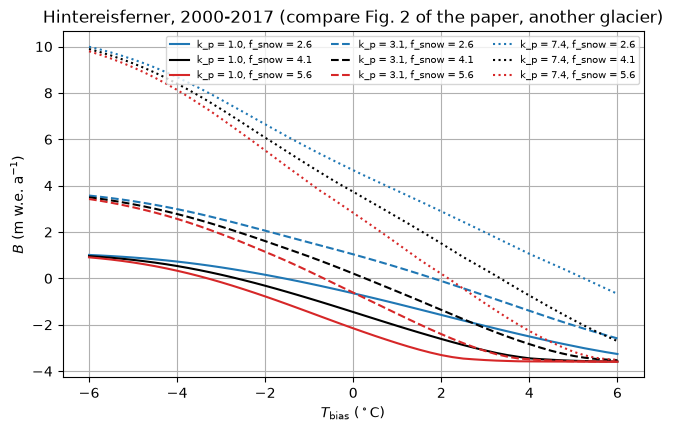

In [3]:
t0 = time.perf_counter()
Tb = np.linspace(-6, 6, 49)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
curves = {}
for kp, ls in [(1.0, '-'), (3.1, '--'), (7.4, ':')]:
    for fs, c in [(2.6, 'tab:blue'), (4.1, 'k'), (5.6, 'tab:red')]:
        curves[kp, fs] = np.array([pm.mass_balance((kp, t, fs)) for t in Tb])
        ax.plot(Tb, curves[kp, fs], ls=ls, color=c, label=f'k_p = {kp}, f_snow = {fs}')
ax.set_xlabel(r'$T_{\mathrm{bias}}$ ($^\circ$C)')
ax.set_ylabel(qlabel)
ax.set_title('Hintereisferner, 2000-2017 (compare Fig. 2 of the paper, another glacier)')
ax.legend(fontsize=7, ncol=3, loc='upper right')
ax.grid(True)
plt.close(fig)
lo_all = min(v.min() for v in curves.values())
hi_all = max(v.max() for v in curves.values())
print(f'{len(curves) * len(Tb)} runs in {time.perf_counter() - t0:.0f} s; B over the 9 curves from {lo_all:.3f} to {hi_all:.3f}')
print(f'k_p = 1, f_snow = 4.1: B = {curves[1.0, 4.1][0]:.3f} at T_bias = -6 and {curves[1.0, 4.1][-1]:.3f} at +6')
fig

As in Fig. 2, $B$ falls with $T_{\mathrm{bias}}$ along S-shaped curves that move to warmer temperatures as $k_p$ grows and to colder ones as $f_{\mathrm{snow}}$ grows. For $k_p = 1$, $f_{\mathrm{snow}} = 4.1$ the curve runs from 0.961 m w.e. a$^{-1}$ at −6 °C to −3.583 at +6 °C. The curves differ from the paper's in level and span (here −3.595 to 9.992 over the nine curves) because the glacier, its climate and its thickness differ (Fig. 2's curves level off near +1.1 and −1.5 m w.e. a$^{-1}$, read from the figure).

### Load data

`generate_data.py` drew $M = 1000$ independent Monte Carlo samples, uniform on each box (seeds 601 and 602), and wrote the physical inputs, $B$ with the glacier area and volume at the end of 2017, and the complex-step gradients $\partial B/\partial x$ in physical units (the exact derivative of the branch the model takes; see below). It takes about 5 minutes (see `DATA.md`).

In [4]:
X3 = np.loadtxt('inputs_m3.csv', delimiter=',')        # (M, 3) k_p, T_bias, f_snow
f3 = np.loadtxt('outputs_m3.csv', delimiter=',')       # (M, 3) B, area 2017, volume 2017
G3 = np.loadtxt('gradients_m3.csv', delimiter=',')     # (M, 3) dB/dx, physical units
X5 = np.loadtxt('inputs_m5.csv', delimiter=',')        # (M, 5) + d_prec, T_snow
f5 = np.loadtxt('outputs_m5.csv', delimiter=',')
G5 = np.loadtxt('gradients_m5.csv', delimiter=',')
print(f'm3: inputs {X3.shape}, outputs {f3.shape}, gradients {G3.shape}; '
      f'm5: inputs {X5.shape}, outputs {f5.shape}, gradients {G5.shape}')

m3: inputs (1000, 3), outputs (1000, 3), gradients (1000, 3); m5: inputs (1000, 5), outputs (1000, 3), gradients (1000, 5)


We check the files against the model at five rows of each study, and the gradients there against central differences with a step of $10^{-7}$ times the box width (small enough to stay on one branch; see below), count draws outside the model's meaning, and compare the least-squares slope of $B$ with the mean gradient.

In [5]:
rows = [0, 1, 2, 3, 4]
for name, X, f, G, names in [('m3', X3, f3, G3, pm.NAMES3), ('m5', X5, f5, G5, pm.NAMES5)]:
    lo = np.array([BOX[n][0] for n in names])
    hi = np.array([BOX[n][1] for n in names])
    fm = pm.mass_balances(X[rows])
    err = []
    for i in rows:
        h = 1e-7 * (hi - lo)
        gfd = np.array([(pm.mass_balance(X[i] + h[j] * e) - pm.mass_balance(X[i] - h[j] * e)) / (2 * h[j])
                        for j, e in enumerate(np.eye(len(names)))])
        s = (hi - lo) / 2
        err.append(np.linalg.norm((gfd - G[i]) * s) / np.linalg.norm(G[i] * s))
    print(f'{name}: model vs outputs at rows {rows}: max |difference| {np.abs(fm - f[rows, 0]).max():.1e} m w.e. a-1; '
          f'gradients vs central differences (step 1e-7 x box width): max relative error {max(err):.1e}')
    inside = np.all((X >= lo) & (X <= hi))
    print(f'    all draws inside the box: {inside}; B in [{f[:, 0].min():.3f}, {f[:, 0].max():.3f}]; '
          f'draws with B < 0: {(f[:, 0] < 0).sum()}; area at the end of 2017 in [{f[:, 1].min():.3f}, {f[:, 1].max():.3f}] km2 '
          f'(initial {pm.AREA0.sum():.4f}); draws that lose all ice: {(f[:, 1] == 0).sum()}; '
          f'that grow by more than 25 %: {(f[:, 1] > 1.25 * pm.AREA0.sum()).sum()}')
# least-squares slope of B on the box-normalized inputs against the mean box-normalized gradient
for name, X, f, G, names in [('m3', X3, f3, G3, pm.NAMES3), ('m5', X5, f5, G5, pm.NAMES5)]:
    lo = np.array([BOX[n][0] for n in names])
    hi = np.array([BOX[n][1] for n in names])
    Z = 2 * (X - lo) / (hi - lo) - 1
    b = np.linalg.lstsq(np.column_stack([np.ones(len(Z)), Z]), f[:, 0], rcond=None)[0][1:]
    g = (G * (hi - lo) / 2).mean(0)
    print(f'{name}: least-squares slope {np.array2string(b, precision=3)}, mean gradient {np.array2string(g, precision=3)} '
          f'(box-normalized); cosine {b @ g / np.linalg.norm(b) / np.linalg.norm(g):.5f}')

m3: model vs outputs at rows [0, 1, 2, 3, 4]: max |difference| 0.0e+00 m w.e. a-1; gradients vs central differences (step 1e-7 x box width): max relative error 7.4e-10
    all draws inside the box: True; B in [-3.519, 2.410]; draws with B < 0: 664; area at the end of 2017 in [0.871, 9.714] km2 (initial 8.0325); draws that lose all ice: 0; that grow by more than 25 %: 0


m5: model vs outputs at rows [0, 1, 2, 3, 4]: max |difference| 0.0e+00 m w.e. a-1; gradients vs central differences (step 1e-7 x box width): max relative error 4.2e-07
    all draws inside the box: True; B in [-3.471, 2.373]; draws with B < 0: 636; area at the end of 2017 in [1.211, 9.684] km2 (initial 8.0325); draws that lose all ice: 0; that grow by more than 25 %: 0
m3: least-squares slope [ 1.131 -1.281 -1.527], mean gradient [ 1.113 -1.231 -1.491] (box-normalized); cosine 0.99995
m5: least-squares slope [ 1.15  -1.243 -1.504 -0.035  0.082], mean gradient [ 1.125 -1.209 -1.465 -0.005  0.11 ] (box-normalized); cosine 0.99982


The model reproduces the stored outputs at these rows to rounding (no difference at the printed precision), and the complex-step gradients agree with central differences to $7.4\times10^{-10}$ (m3) and $4.2\times10^{-7}$ (m5). **The gradient is that of the branch the model takes.** $B$ is piecewise smooth: it jumps by small amounts when a bin changes surface type (snow or firn to ice, which changes its degree-day factor), when the glacier advances by a bin, and at the other thresholds of the code. `check_accuracy.py` finds the largest jump in a 2001-point scan of $T_{\mathrm{bias}}$ over 1 °C to be $2.8\times10^{-4}$ m w.e. a$^{-1}$, less than $10^{-4}$ of the range of $B$ in study m3 (−3.519 to 2.410, below); central differences with steps of $10^{-3}$ to $10^{-6}$ box widths straddle such jumps and differ from the complex step by up to $10^{-2}$ (relative), while a step of $10^{-7}$ agrees to $3\times10^{-7}$ or better. **The jumps add up**, so the branch derivative is not always the slope of the response. Along a 481-point scan of $k_p$ over its box (other inputs nominal) the branch derivative departs by more than 5 % from its running median at 1.2 % of the points; at $k_p = 1.944$ it is −0.690 against a trend of +0.785 (central differences with steps of $10^{-9}$ to $10^{-7}$ confirm it: it is the model's branch, not a coding error), and its integral over the scan falls short of the change of $B$ by 1.1 % (1.0 % for $T_{\mathrm{snow}}$; for the nearly inactive $d_{\mathrm{prec}}$ $B$ changes by only $10^{-3}$ m w.e. a$^{-1}$ over the box and the jumps dominate). Over all 1000 rows of study m3 the complex-step gradients differ from a smoothed central difference (step 0.005 box widths, which follows the response across the jumps) by a median of 0.77 %, by more than 10 % at 30 rows and more than 50 % at 2 (smallest direction cosine 0.9935); the active subspace is unaffected: $\lambda_1/\lambda_2 = 29.55$ from the smoothed gradients against 29.60, and $\mathbf w_1$ moves by at most $1.3\times10^{-3}$ per entry (`check_accuracy.py`, checks 5 and 6). The least-squares slope of $B$ on the box-normalized inputs points in the direction of the mean gradient (cosine 0.99995 in m3 and 0.99982 in m5); in m5 they differ most for the nearly inactive $d_{\mathrm{prec}}$ (−0.035 against −0.005), where noise and the jumps dominate. Every draw keeps ice: the area at the end of 2017 ranges from 0.871 to 9.714 km$^2$ (initial 8.0325), and 664 of 1000 draws (m3) have $B < 0$.

### Estimate the active subspace

The model is cheap and smooth between its small jumps, so we use the complex-step gradients (`estimator='as'`; exact for the branch taken, checked above), $M = 1000$, and 500 bootstrap replicates with `rng=SEED`. Eigenvector signs: the paper has no eigenvectors, so we orient each so that $B$ increases along it (`ac.orient(by='covariance')`).

In [6]:
lo3 = [BOX[n][0] for n in pm.NAMES3]
hi3 = [BOX[n][1] for n in pm.NAMES3]
space3 = ac.Uniform(lo3, hi3, names=list(pm.NAMES3))
sub3 = ac.active_subspace(space=space3, X=X3, f=f3[:, 0], grads=G3, estimator='as', nboot=500, rng=SEED)
sub3 = ac.orient(sub3, by='covariance', X=X3, f=f3[:, 0], columns=3)
lam3 = sub3.eigenvalues
b3 = sub3.bootstrap_eigenvalues
ks, crit, k_hat = ac.dimension_criterion(sub3, rule='evg')
print(f'm3: eigenvalues {np.array2string(lam3, precision=5)}; n = {sub3.n} (gap rule {k_hat})')
print(f'    lambda_1/lambda_2 = {lam3[0] / lam3[1]:.1f} (2.5-97.5 % over replicates '
      f'[{np.percentile(b3[:, 0] / b3[:, 1], 2.5):.1f}, {np.percentile(b3[:, 0] / b3[:, 1], 97.5):.1f}]), '
      f'lambda_2/lambda_3 = {lam3[1] / lam3[2]:.2f} ([{np.percentile(b3[:, 1] / b3[:, 2], 2.5):.2f}, '
      f'{np.percentile(b3[:, 1] / b3[:, 2], 97.5):.2f}])')
print(f'    share of sum(lambda) left out by n = 1: {lam3[1:].sum() / lam3.sum():.4f}; by n = 2: {lam3[2] / lam3.sum():.5f}; '
      f'share in lambda_2: {lam3[1] / lam3.sum():.4f}')

m3: eigenvalues [5.11143 0.17271 0.07951]; n = 1 (gap rule 1)
    lambda_1/lambda_2 = 29.6 (2.5-97.5 % over replicates [27.5, 32.0]), lambda_2/lambda_3 = 2.17 ([1.94, 2.46])
    share of sum(lambda) left out by n = 1: 0.0470; by n = 2: 0.01482; share in lambda_2: 0.0322


### Results

**Eigenvalues and subspace errors** (study m3).

lambda_1 = 5.11143, 95 % bootstrap interval [5.01927, 5.21314]
lambda_2 = 0.17271, 95 % bootstrap interval [0.15920, 0.18668]
lambda_3 = 0.07951, 95 % bootstrap interval [0.07344, 0.08488]
bootstrap mean subspace distance: n = 1: 0.00642, n = 2: 0.0245


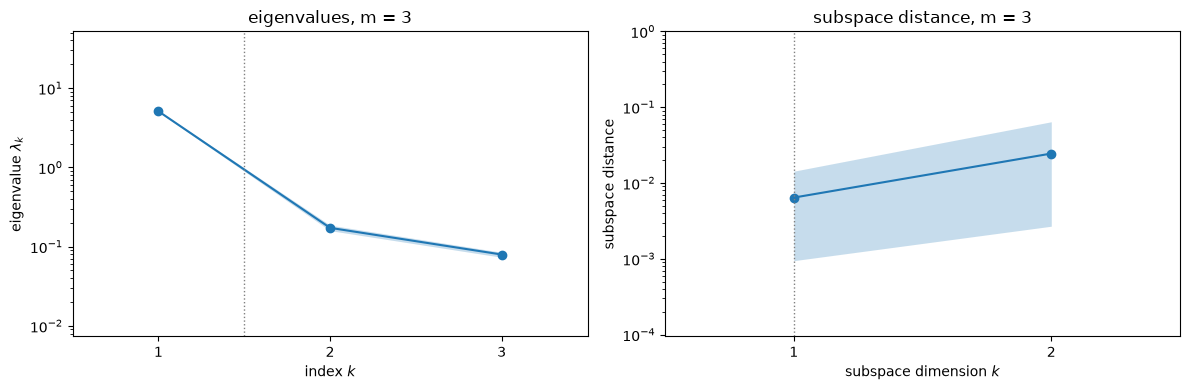

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ac.plotting.plot_eigenvalues(sub3, ax=axes[0])
axes[0].set_title('eigenvalues, m = 3')
ac.plotting.plot_subspace_errors(sub3, ax=axes[1])
axes[1].set_title('subspace distance, m = 3')
fig.tight_layout()
plt.close(fig)
for k in range(3):
    print(f'lambda_{k + 1} = {lam3[k]:.5f}, 95 % bootstrap interval [{np.percentile(b3[:, k], 2.5):.5f}, {np.percentile(b3[:, k], 97.5):.5f}]')
print('bootstrap mean subspace distance: ' + ', '.join(f'n = {k + 1}: {d:.3g}' for k, d in enumerate(sub3.bootstrap_distances.mean(axis=0))))
fig

$\lambda_1 = 5.111$ (95 % bootstrap interval $[5.019, 5.213]$), $\lambda_2 = 0.173$ and $\lambda_3 = 0.0795$, so $\lambda_1/\lambda_2 = 29.6$ (27.5–32.0 over the replicates), while $\lambda_2/\lambda_3 = 2.17$ is small. **We choose $n = 1$**: the gap after $\lambda_1$ is the only large one (the eigenvalue-gap rule also picks 1), the subspace distance for $n = 1$ is 0.0064 against 0.0245 for $n = 2$, and $\lambda_2 + \lambda_3$ is 4.7 % of the sum ($\lambda_3$ alone 1.5 %). The second direction is not negligible, though: $\lambda_2 = 0.173$ is more than twice $\lambda_3$, and it raises the surrogate fit (below). The size of the gap belongs to this box: on a wider and a narrower box ("Sensitivity to the box", below) $\lambda_1/\lambda_2$ is 25.8 and 115.2, while the one-dimensional structure holds on all three.

w1 = [ 0.4886 -0.5535 -0.6745]  (k_p, T_bias, f_snow; box-normalized)
w2 = [ 0.1322 -0.7172  0.6842]  (k_p, T_bias, f_snow; box-normalized)
w3 = [-0.8624 -0.4235 -0.2773]  (k_p, T_bias, f_snow; box-normalized)
activity scores (n = 1), normalized: [0.2387 0.3063 0.4549]


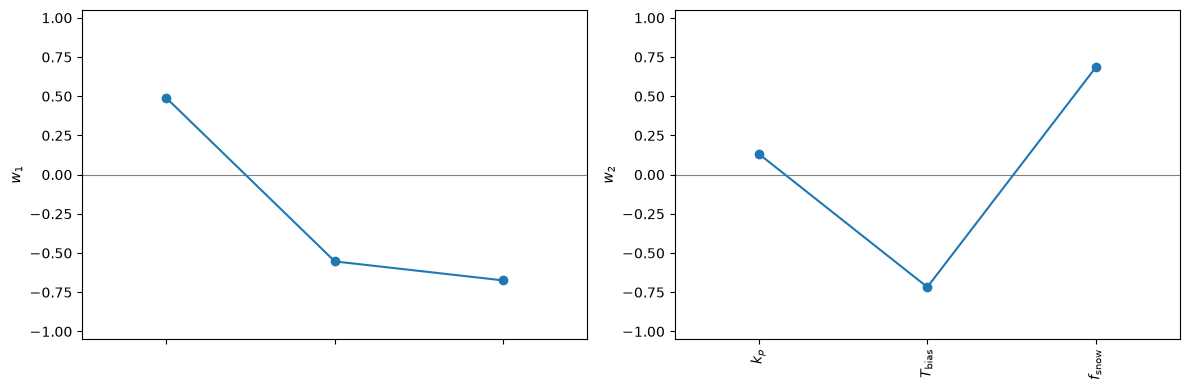

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ac.plotting.plot_eigenvectors(sub3, indices=[0, 1], labels=[sym[n] for n in pm.NAMES3], ax=list(axes))
fig.tight_layout()
plt.close(fig)
W3 = sub3.W
for k in range(3):
    print(f'w{k + 1} = {np.array2string(W3[:, k], precision=4)}  ({", ".join(pm.NAMES3)}; box-normalized)')
alpha3 = ac.activity_scores(sub3, n=1)
print(f'activity scores (n = 1), normalized: {np.array2string(alpha3 / alpha3.sum(), precision=4)}')
fig

$\mathbf w_1 = (0.4886, -0.5535, -0.6745)$ for $(k_p, T_{\mathrm{bias}}, f_{\mathrm{snow}})$ in box-normalized coordinates: $B$ grows with more precipitation and falls with warmer temperatures and faster melt, and on this box the three enter with comparable weights (normalized activity scores 0.239, 0.306, 0.455). These box-normalized weights depend on how far the box lets each input range; the direction per physical unit is more stable ("Sensitivity to the box", below). Moving along any direction orthogonal to $\mathbf w_1$ trades the three against each other at nearly constant $B$; this is the non-identifiability of Sec. 3.4 (p. 179) and Sec. 4.3 (p. 182) seen as geometry. $\mathbf w_2 = (0.1322, -0.7172, 0.6842)$ is mainly a trade of $T_{\mathrm{bias}}$ against $f_{\mathrm{snow}}$, the two ablation parameters: their effects on melt are not interchangeable, because $T_{\mathrm{bias}}$ also shifts the snow/rain split and the months with melt.

y1 in [-1.53, 1.51], corr(y1, B) = 0.98401; y2 in [-1.36, 1.48]


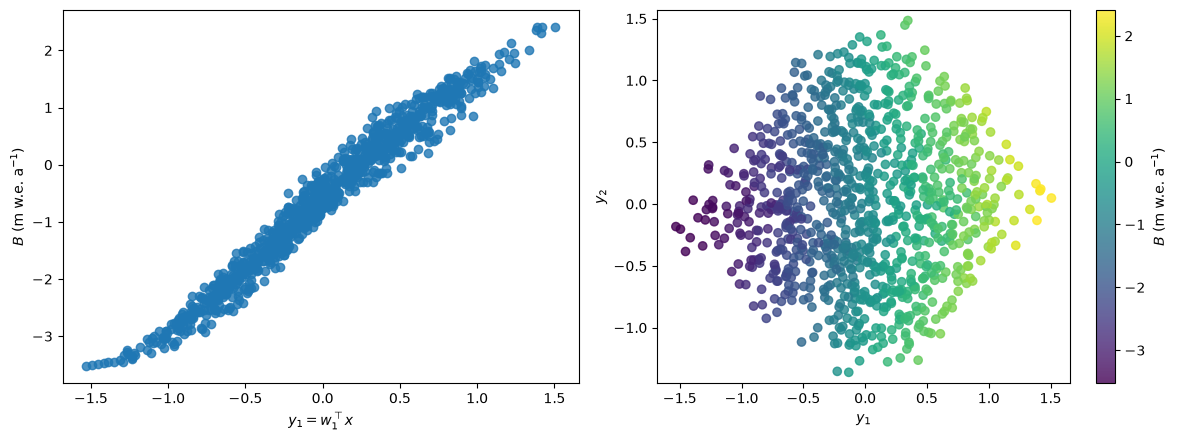

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(sub3, X=X3, f=f3[:, 0], dims=1, qoi_label=qlabel, ax=axes[0])
ac.plotting.plot_sufficient_summary(ac.with_dimension(sub3, 2), X=X3, f=f3[:, 0], dims=2, qoi_label=qlabel, ax=axes[1])
fig.tight_layout()
plt.close(fig)
XN3 = space3.to_normalized(X3)
Y3 = XN3 @ W3
print(f'y1 in [{Y3[:, 0].min():.2f}, {Y3[:, 0].max():.2f}], corr(y1, B) = {np.corrcoef(Y3[:, 0], f3[:, 0])[0, 1]:.5f}; '
      f'y2 in [{Y3[:, 1].min():.2f}, {Y3[:, 1].max():.2f}]')
fig

The one-dimensional summary plot is a tight, nearly linear trend that flattens at the lowest values, with $\mathrm{corr}(y_1, B) = 0.98401$ over $y_1 \in [-1.53, 1.51]$. The scatter about it is the second direction: in the two-dimensional plot the colour also changes along $y_2$, as $\lambda_2/\lambda_1 = 1/29.6$ allows.

#### Surrogates on the active variables

Polynomials in $y_1$ (degrees 1–3) and a quadratic in $(y_1, y_2)$, with leave-one-out $R^2$.

linear, n = 1     LOO R^2 = 0.96815
quadratic, n = 1  LOO R^2 = 0.96868
cubic, n = 1      LOO R^2 = 0.97204
quadratic, n = 2  LOO R^2 = 0.98830
gain in LOO R^2 from the second active variable (quadratic, n = 2 against cubic, n = 1): 0.01626


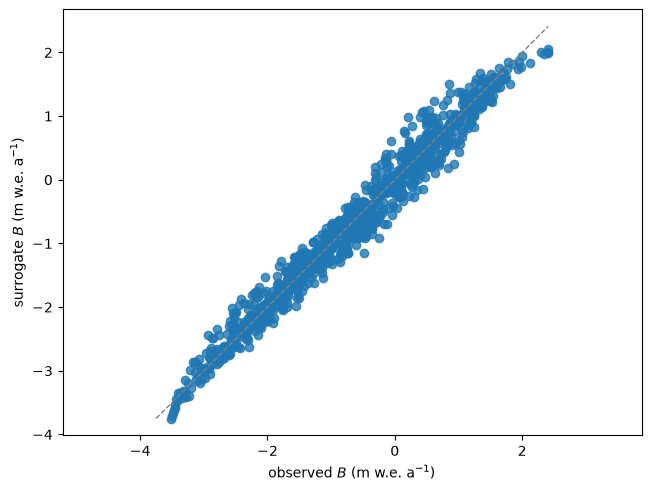

In [10]:
surs3 = {}
for name, s_k, deg in [('linear, n = 1', sub3, 1), ('quadratic, n = 1', sub3, 2), ('cubic, n = 1', sub3, 3),
                       ('quadratic, n = 2', ac.with_dimension(sub3, 2), 2)]:
    s = ac.fit_surrogate(X=X3, f=f3[:, 0], subspace=s_k, kind='poly', degree=deg)
    surs3[name] = s
    print(f'{name:17s} LOO R^2 = {s.loo_r_squared:.5f}')
print(f'gain in LOO R^2 from the second active variable (quadratic, n = 2 against cubic, n = 1): '
      f'{surs3["quadratic, n = 2"].loo_r_squared - surs3["cubic, n = 1"].loo_r_squared:.5f}')
fig, ax = ac.plotting.plot_surrogate_fit(surs3['cubic, n = 1'], X=X3, f=f3[:, 0], qoi_label=qlabel)
plt.close(fig)
fig

A line in $y_1$ already has leave-one-out $R^2 = 0.96815$; quadratic and cubic terms add little (0.96868, 0.97204). A quadratic in two active variables reaches 0.98830, a gain of 0.01626 over the cubic in $y_1$; $\lambda_2$ holds 0.0322 of the eigenvalue sum. For the uses below (a single mass-balance observation) one variable is the main story.

#### Study m5: freeing the precipitation gradient and the snow/rain threshold

The same estimate with $d_{\mathrm{prec}} \in [0, 2\times10^{-4}]$ m$^{-1}$ and $T_{\mathrm{snow}} \in [0, 2]$ °C added (this data set's choice; the paper fixes them, p. 177).

In [11]:
lo5 = [BOX[n][0] for n in pm.NAMES5]
hi5 = [BOX[n][1] for n in pm.NAMES5]
space5 = ac.Uniform(lo5, hi5, names=list(pm.NAMES5))
sub5 = ac.active_subspace(space=space5, X=X5, f=f5[:, 0], grads=G5, estimator='as', nboot=500, rng=SEED)
sub5 = ac.orient(sub5, by='covariance', X=X5, f=f5[:, 0], columns=5)
lam5 = sub5.eigenvalues
b5 = sub5.bootstrap_eigenvalues
ks5, crit5, k_hat5 = ac.dimension_criterion(sub5, rule='evg')
print(f'm5: eigenvalues {np.array2string(lam5, precision=5)}; n = {sub5.n} (gap rule {k_hat5})')
print('    ratios lambda_k/lambda_k+1: ' + ', '.join(f'{lam5[k] / lam5[k + 1]:.2f} [{np.percentile(b5[:, k] / b5[:, k + 1], 2.5):.2f}, '
      f'{np.percentile(b5[:, k] / b5[:, k + 1], 97.5):.2f}]' for k in range(4)))
print(f'    share of sum(lambda) left out by n = 1: {lam5[1:].sum() / lam5.sum():.4f}')
for k in range(2):
    print(f'    w{k + 1} = {np.array2string(sub5.W[:, k], precision=4)}  ({", ".join(pm.NAMES5)})')
print('    bootstrap mean subspace distance: ' + ', '.join(f'n = {k + 1}: {d:.3g}' for k, d in enumerate(sub5.bootstrap_distances.mean(axis=0))))
print(f'    angle between w1 (m3) and the first three entries of w1 (m5), renormalized: '
      f'{np.degrees(np.arccos(abs(sub3.W[:, 0] @ sub5.W[:3, 0]) / np.linalg.norm(sub5.W[:3, 0]))):.2f} deg')
for name, s_k, deg in [('quadratic, n = 1', sub5, 2), ('cubic, n = 1', sub5, 3), ('quadratic, n = 2', ac.with_dimension(sub5, 2), 2)]:
    print(f'    {name:17s} LOO R^2 = {ac.fit_surrogate(X=X5, f=f5[:, 0], subspace=s_k, kind="poly", degree=deg).loo_r_squared:.5f}')
zg = pm.Z_BINS[pm.AREA0 > 0]
print(f'largest |d_prec (z_bin - z_ref)| over the glacier bins at d_prec = {BOX["d_prec"][1]:g} m-1: '
      f'{100 * BOX["d_prec"][1] * np.abs(zg - pm.Z_MED).max():.1f} %')

m5: eigenvalues [5.01001e+00 1.65163e-01 8.22620e-02 2.32374e-03 4.63722e-06]; n = 1 (gap rule 1)
    ratios lambda_k/lambda_k+1: 30.33 [28.17, 32.63], 2.01 [1.79, 2.27], 35.40 [32.25, 39.06], 501.11 [450.47, 568.17]
    share of sum(lambda) left out by n = 1: 0.0475
    w1 = [ 0.4988 -0.5489 -0.6688 -0.0022  0.0501]  (k_p, T_bias, f_snow, d_prec, T_snow)
    w2 = [-0.0893  0.7345 -0.6719  0.0015 -0.0333]  (k_p, T_bias, f_snow, d_prec, T_snow)
    bootstrap mean subspace distance: n = 1: 0.00661, n = 2: 0.0264, n = 3: 0.00588, n = 4: 0.00119
    angle between w1 (m3) and the first three entries of w1 (m5), renormalized: 0.71 deg
    quadratic, n = 1  LOO R^2 = 0.97153
    cubic, n = 1      LOO R^2 = 0.97324
    quadratic, n = 2  LOO R^2 = 0.98879
largest |d_prec (z_bin - z_ref)| over the glacier bins at d_prec = 0.0002 m-1: 12.3 %


m5: corr(y1, B) = 0.98540


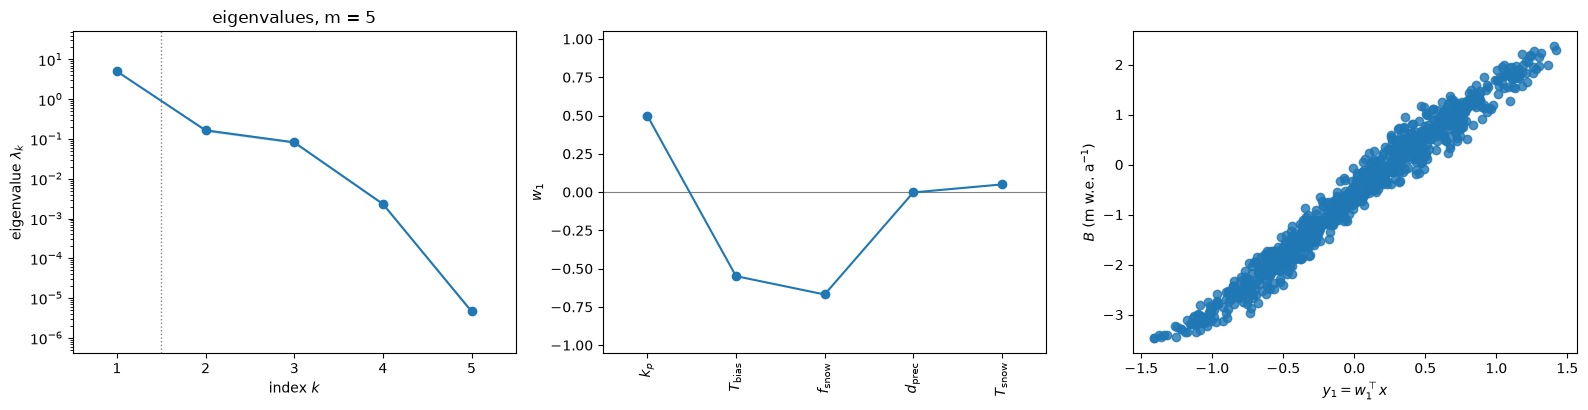

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ac.plotting.plot_eigenvalues(sub5, ax=axes[0])
axes[0].set_title('eigenvalues, m = 5')
ac.plotting.plot_eigenvectors(sub5, indices=[0], labels=[sym[n] for n in pm.NAMES5], ax=[axes[1]])
ac.plotting.plot_sufficient_summary(sub5, X=X5, f=f5[:, 0], dims=1, qoi_label=qlabel, ax=axes[2])
fig.tight_layout()
plt.close(fig)
y5 = space5.to_normalized(X5) @ sub5.W[:, 0]
print(f'm5: corr(y1, B) = {np.corrcoef(y5, f5[:, 0])[0, 1]:.5f}')
fig

With five inputs the eigenvalues are 5.010, 0.165, 0.0823, $2.3\times10^{-3}$ and $4.6\times10^{-6}$: $\lambda_1/\lambda_2 = 30.33$ (28.17–32.63), $\lambda_2/\lambda_3 = 2.01$, and the two new inputs add two nearly inactive directions ($\lambda_3/\lambda_4 = 35.40$, $\lambda_4/\lambda_5 = 501.11$). $\mathbf w_1 = (0.4988, -0.5489, -0.6688, -0.0022, 0.0501)$ gives $d_{\mathrm{prec}}$ and $T_{\mathrm{snow}}$ almost no weight, and its first three entries are 0.71° from the m3 direction. A quadratic in $y_1$ has leave-one-out $R^2 = 0.97153$ (cubic 0.97324; quadratic in two variables 0.98879). We choose $n = 1$ again. On this glacier the precipitation gradient barely matters: even at the top of its range it changes precipitation by at most 12.3 % at the glacier's highest and lowest bins (printed above), and the bins are spread on both sides of the reference elevation; the snow threshold acts only in months with temperatures near it.

#### Sensitivity to the box

The box is this data set's choice, and the normalization to $[-1, 1]$ ties both the eigenvalues and the box-normalized weights to it. We repeat the estimate of study m3 on two other boxes, also this data set's choice: a wider one ($k_p \in [0.5, 6]$, $T_{\mathrm{bias}} \in [-3, 3]$ °C, $f_{\mathrm{snow}}$ as before) and a narrower one near the Huss–Hock range of $k_p$ (0.8–2.0, p. 186) and the core of the priors ($T_{\mathrm{bias}} \in [-1, 1]$ °C, $f_{\mathrm{snow}} \in [2.6, 5.6]$, $\mu \pm \sigma$ of Eq. 16), each with 300 new uniform draws (seed `SEED`) and 200 bootstrap replicates. Besides $\mathbf w_1$ in box-normalized coordinates we print the direction in physical units per box half-width removed, $\mathbf w_1 / \mathbf h$ normalized ($\mathbf h$ the half-widths), which does not depend on the box when the gradient direction does not.

In [13]:
t0 = time.perf_counter()
boxes = {'shipped': (np.array(lo3), np.array(hi3)),
         'wider': (np.array([0.5, -3.0, 1.1]), np.array([6.0, 3.0, 7.1])),
         'narrower': (np.array([0.8, -1.0, 2.6]), np.array([2.0, 1.0, 5.6]))}
rng_box = np.random.default_rng(SEED)
box_res = {}
for name, (lo, hi) in boxes.items():
    if name == 'shipped':
        X, f, G = X3, f3[:, 0], G3
    else:
        X = lo + (hi - lo) * rng_box.random((300, 3))
        f, G = pm.mass_balances(X, grad=True)
    sp = ac.Uniform(lo, hi, names=list(pm.NAMES3))
    s = ac.active_subspace(space=sp, X=X, f=f, grads=G, estimator='as', nboot=200, rng=SEED)
    s = ac.orient(s, by='covariance', X=X, f=f, columns=3)
    lam, b = s.eigenvalues, s.bootstrap_eigenvalues
    w = s.W[:, 0]
    wp = w / ((hi - lo) / 2)
    wp /= np.linalg.norm(wp)
    a = ac.activity_scores(s, n=1)
    r2 = ac.fit_surrogate(X=X, f=f, subspace=s, kind='poly', degree=3).loo_r_squared
    box_res[name] = (lam[0] / lam[1], wp)
    print(f'{name:8s} box {np.array2string(lo, precision=1)} to {np.array2string(hi, precision=1)}, M = {len(X)}: '
          f'lambda1/lambda2 = {lam[0] / lam[1]:.1f} [{np.percentile(b[:, 0] / b[:, 1], 2.5):.1f}, '
          f'{np.percentile(b[:, 0] / b[:, 1], 97.5):.1f}], lambda2/lambda3 = {lam[1] / lam[2]:.2f}; '
          f'left out by n = 1: {lam[1:].sum() / lam.sum():.4f}; cubic in y1 LOO R^2 = {r2:.4f}')
    print(f'         w1 (box-normalized) {np.array2string(w, precision=3)}; normalized activity scores '
          f'{np.array2string(a / a.sum(), precision=3)}; w1/h normalized {np.array2string(wp, precision=3)}; '
          f'B in [{f.min():.2f}, {f.max():.2f}]')
ref = box_res['shipped'][1]
print('angle between the w1/h directions and that of the shipped box: ' +
      ', '.join(f'{k} {np.degrees(np.arccos(min(1.0, abs(v[1] @ ref)))):.1f} deg' for k, v in box_res.items() if k != 'shipped') +
      f'; {time.perf_counter() - t0:.0f} s')

shipped  box [ 0.5 -2.   1.1] to [3.5 2.  7.1], M = 1000: lambda1/lambda2 = 29.6 [27.5, 31.9], lambda2/lambda3 = 2.17; left out by n = 1: 0.0470; cubic in y1 LOO R^2 = 0.9720
         w1 (box-normalized) [ 0.489 -0.553 -0.674]; normalized activity scores [0.239 0.306 0.455]; w1/h normalized [ 0.674 -0.573 -0.466]; B in [-3.52, 2.41]


wider    box [ 0.5 -3.   1.1] to [6.  3.  7.1], M = 300: lambda1/lambda2 = 25.8 [23.4, 29.1], lambda2/lambda3 = 1.39; left out by n = 1: 0.0624; cubic in y1 LOO R^2 = 0.9555
         w1 (box-normalized) [ 0.613 -0.647 -0.454]; normalized activity scores [0.376 0.418 0.206]; w1/h normalized [ 0.646 -0.625 -0.438]; B in [-3.57, 4.75]


narrower box [ 0.8 -1.   2.6] to [2.  1.  5.6], M = 300: lambda1/lambda2 = 115.2 [100.6, 134.6], lambda2/lambda3 = 2.93; left out by n = 1: 0.0115; cubic in y1 LOO R^2 = 0.9924
         w1 (box-normalized) [ 0.42  -0.562 -0.712]; normalized activity scores [0.176 0.316 0.508]; w1/h normalized [ 0.689 -0.554 -0.468]; B in [-2.65, 0.44]
angle between the w1/h directions and that of the shipped box: wider 3.7 deg, narrower 1.4 deg; 53 s


On the shipped box $\lambda_1/\lambda_2 = 29.6$; on the wider box it is 25.8 (bootstrap [23.4, 29.1]) and on the narrower box 115.2 ([100.6, 134.6]). The one-dimensional structure holds on all three (a cubic in $y_1$ has leave-one-out $R^2$ 0.9720, 0.9555 and 0.9924; $n = 1$ leaves out 0.0470, 0.0624 and 0.0115 of the eigenvalue sum), but the size of the gap is set by the box. So are the box-normalized weights: $\mathbf w_1$ = (0.489, −0.553, −0.674), (0.613, −0.647, −0.454) and (0.42, −0.562, −0.712), with normalized activity scores (0.239, 0.306, 0.455), (0.376, 0.418, 0.206) and (0.176, 0.316, 0.508): which input "matters most" depends on how far each may range. The direction per physical unit is stable: $\mathbf w_1/\mathbf h$ normalized is (0.674, −0.573, −0.466), (0.646, −0.625, −0.438) and (0.689, −0.554, −0.468), 3.7° and 1.4° from the shipped box's. On the wider box the second gap shrinks ($\lambda_2/\lambda_3 = 1.39$ against 2.17) and $B$ reaches 4.75 m w.e. a$^{-1}$.

#### The paper's non-identifiability, seen through $\mathbf w_1$

The paper calibrates each glacier against one observation and finds that the posterior correlates the parameters (Sec. 4.3, p. 182). We sketch the same effect here with a synthetic observation (this data set's choice: $B_{\mathrm{obs}}$ = $B$ at the nominal point, sd 0.31 m w.e. a$^{-1}$, the median observation uncertainty on p. 177) and the uniform box as prior, by weighting the 1000 model runs with the Gaussian likelihood. This is not the paper's MCMC.

synthetic observation B_obs = -1.4510, sigma = 0.31; effective sample size 244 of 1000
  weighted correlation k_p-T_bias: +0.545 (bootstrap 95 % [+0.457, +0.625])
  weighted correlation k_p-f_snow: +0.282 (bootstrap 95 % [+0.166, +0.389])
  weighted correlation T_bias-f_snow: -0.535 (bootstrap 95 % [-0.603, -0.453])
  weighted mean (sd): k_p 1.791 (0.862), T_bias 0.231 (1.017), f_snow 4.951 (1.219); prior sd: 0.866, 1.155, 1.732
  weighted sd of the active and inactive variables (y1, y2, y3) = [0.145 0.553 0.653]; unweighted: [0.56  0.59  0.579]


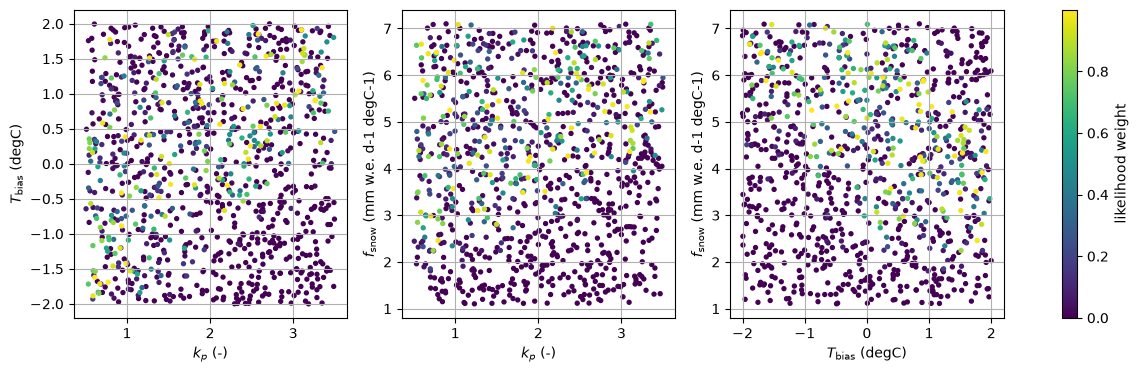

In [14]:
# Sketch of the paper's identifiability argument for this glacier. This data set's choices: a synthetic
# observation B_obs = B at the nominal point with sd sigma = 0.31 m w.e. a-1 (the median uncertainty of the
# paper's observations, p. 177) and the uniform box as the prior. Likelihood weights on the 1000 model runs.
B_obs, sigma = B0['B'].real, 0.31
w = np.exp(-0.5 * ((f3[:, 0] - B_obs) / sigma) ** 2)
ess = w.sum() ** 2 / (w ** 2).sum()
pairs = [(0, 1), (0, 2), (1, 2)]


def wcorr(X, w):
    mu = (w[:, None] * X).sum(0) / w.sum()
    C = ((w[:, None] * (X - mu)).T @ (X - mu)) / w.sum()
    d = np.sqrt(np.diag(C))
    return C / np.outer(d, d), mu, d


R, mu, sd = wcorr(X3, w)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(w), len(w))
    boot.append([wcorr(X3[i], w[i])[0][a, b] for a, b in pairs])
boot = np.array(boot)
print(f'synthetic observation B_obs = {B_obs:.4f}, sigma = {sigma}; effective sample size {ess:.0f} of {len(w)}')
for k, (a, b) in enumerate(pairs):
    print(f'  weighted correlation {pm.NAMES3[a]}-{pm.NAMES3[b]}: {R[a, b]:+.3f} '
          f'(bootstrap 95 % [{np.percentile(boot[:, k], 2.5):+.3f}, {np.percentile(boot[:, k], 97.5):+.3f}])')
print('  weighted mean (sd): ' + ', '.join(f'{n} {m:.3f} ({s:.3f})' for n, m, s in zip(pm.NAMES3, mu, sd)) +
      '; prior sd: ' + ', '.join(f'{(b - a) / np.sqrt(12):.3f}' for a, b in zip(lo3, hi3)))
_, _, sdy = wcorr(Y3, w)
print('  weighted sd of the active and inactive variables (y1, y2, y3) = ' + np.array2string(sdy, precision=3) +
      f'; unweighted: {np.array2string(Y3.std(axis=0), precision=3)}')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
o = np.argsort(w)
for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(X3[o, a], X3[o, b], c=w[o], s=8, cmap='viridis')
    ax.set_xlabel(f'{sym[pm.NAMES3[a]]} ({pm.UNITS[pm.NAMES3[a]]})')
    ax.set_ylabel(f'{sym[pm.NAMES3[b]]} ({pm.UNITS[pm.NAMES3[b]]})')
    ax.grid(True)
fig.colorbar(sc, ax=axes, label='likelihood weight')
plt.close(fig)
fig

The weighted correlations are $k_p$–$T_{\mathrm{bias}}$ +0.545 (bootstrap 95 % [+0.457, +0.625]), $k_p$–$f_{\mathrm{snow}}$ +0.282 ([+0.166, +0.389]) and $T_{\mathrm{bias}}$–$f_{\mathrm{snow}}$ −0.535 ([−0.603, −0.453]), from an effective sample size of 244. The observation narrows the active variable (weighted sd of $y_1$ 0.145 against 0.56 unweighted) and leaves the inactive ones as wide as before or wider (0.553 and 0.653 against 0.59 and 0.579): the data inform the parameters "as a group" (p. 182) through $y_1$ only. The signs follow from $\mathbf w_1$: holding $y_1$ fixed, an increase of $k_p$ must be offset by an increase of $T_{\mathrm{bias}}$ or $f_{\mathrm{snow}}$, and the two ablation parameters offset each other. The values rest on three choices of this data set: the uniform box as prior, the synthetic observation at the nominal point, and $\sigma = 0.31$.

### Comparison with the paper

The paper does not compute an active subspace or gradients, and it reports no result for Hintereisferner. What can be compared is the structure: the direction of the parameter trade-offs and the response to $T_{\mathrm{bias}}$ (Fig. 2).

In [15]:
print('Paper, p. 179 (RGI60-13.26360, ERA-Interim): three settings (T_bias, k_p, f_snow) that match the observation.')
for tb, kp, fs in [(-2.0, 1.0, 4.1), (0.0, 3.1, 2.6), (0.0, 7.4, 5.6)]:
    print(f'  ({tb:+.0f} degC, {kp}, {fs}): B = {pm.mass_balance((kp, tb, fs)):+.4f} m w.e. a-1 for Hintereisferner; '
          f'y1 = {space3.to_normalized(np.array([[kp, tb, fs]]))[0] @ W3[:, 0]:+.3f}' +
          ('' if lo3[0] <= kp <= hi3[0] else ' (k_p outside the box)'))
print(f'\nsigns of w1 (k_p, T_bias, f_snow): {np.sign(W3[:, 0]).astype(int).tolist()}')

Paper, p. 179 (RGI60-13.26360, ERA-Interim): three settings (T_bias, k_p, f_snow) that match the observation.
  (-2 degC, 1.0, 4.1): B = -0.3164 m w.e. a-1 for Hintereisferner; y1 = +0.228
  (+0 degC, 3.1, 2.6): B = +1.0384 m w.e. a-1 for Hintereisferner; y1 = +0.696
  (+0 degC, 7.4, 5.6): B = +2.8277 m w.e. a-1 for Hintereisferner; y1 = +1.422 (k_p outside the box)

signs of w1 (k_p, T_bias, f_snow): [1, -1, -1]


| Quantity | Paper value | Notebook value |
|---|---|---|
| glacier, forcing, period | RGI60-13.26360 and all of High Mountain Asia; ERA-Interim; 2000–2018 (pp. 177, 179) | Hintereisferner RGI60-11.00897; ERA5; Jan 2000–Dec 2017 |
| inputs calibrated | $k_p$, $T_{\mathrm{bias}}$, $f_{\mathrm{snow}}$ (Sec. 2.1, p. 177) | the same (m3); plus $d_{\mathrm{prec}}$, $T_{\mathrm{snow}}$ (m5) |
| active subspace | not reported | $n = 1$; $\lambda_1/\lambda_2 = 29.6$ (m3), 30.33 (m5) on this data set's box; 25.8 and 115.2 (m3) on a wider and a narrower box |
| direction of the trade-off | non-identifiable; parameters informed "as a group" (pp. 179, 182) | $\mathbf w_1 = (0.4886, -0.5535, -0.6745)$; synthetic-observation weights narrow $y_1$ only |
| posterior correlation $k_p$–$T_{\mathrm{bias}}$ | mean +0.39 over the glaciers (p. 182) | +0.545 [+0.457, +0.625] (one glacier, synthetic observation, uniform prior) |
| posterior correlation $k_p$–$f_{\mathrm{snow}}$ | mean +0.33 (p. 182) | +0.282 [+0.166, +0.389] |
| posterior correlation $T_{\mathrm{bias}}$–$f_{\mathrm{snow}}$ | negative (p. 183; value not reported in the text) | −0.535 [−0.603, −0.453] |
| three equifinal settings ($T_{\mathrm{bias}}$, $k_p$, $f_{\mathrm{snow}}$) | (−2, 1, 4.1), (0, 3.1, 2.6), (0, 7.4, 5.6) match RGI60-13.26360's observation (p. 179) | not equifinal for this glacier: $B$ = −0.3164, +1.0384, +2.8277; $k_p = 7.4$ is outside the box |
| $B$ against $T_{\mathrm{bias}}$ | S-shaped, falling, shifted by $k_p$ and $f_{\mathrm{snow}}$ (Fig. 2, p. 179) | the same shape (figure above) |
| model code | PyGEM v0.1.0 (p. 186) | numpy port, equal to PyGEM v0.1 to rounding, of order $10^{-15}$ m w.e. a$^{-1}$ (`check_accuracy.py`) |

The correlations agree in sign with the paper's; $k_p$–$f_{\mathrm{snow}}$ is of similar size (+0.282 against +0.33), $k_p$–$T_{\mathrm{bias}}$ is not (+0.545 against +0.39). They rest on three choices of this data set (the uniform box as prior, the synthetic observation at the nominal point, $\sigma = 0.31$) and are one glacier's, against the paper's means over about 95,000 glaciers with real observations and regional priors; they show the mechanism, not a reproduction.

### References

[1] D. R. Rounce, T. Khurana, M. B. Short, R. Hock, D. E. Shean, and D. J. Brinkerhoff. [Quantifying parameter uncertainty in a large-scale glacier evolution model using Bayesian inference: application to High Mountain Asia](https://doi.org/10.1017/jog.2019.91). *Journal of Glaciology*, 66(256):175–187, 2020. Model code: PyGEM v0.1, <https://github.com/drounce/PyGEM> (tag `v0.1`).

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] M. Huss and R. Hock. [A new model for global glacier change and sea-level rise](https://doi.org/10.3389/feart.2015.00054). *Frontiers in Earth Science*, 3:54, 2015.

[4] D. Farinotti, M. Huss, J. J. Fürst, J. Landmann, H. Machguth, F. Maussion, and A. Pandit. [A consensus estimate for the ice thickness distribution of all glaciers on Earth](https://doi.org/10.1038/s41561-019-0300-3). *Nature Geoscience*, 12(3):168–173, 2019.

[5] H. Hersbach, B. Bell, P. Berrisford, et al. [The ERA5 global reanalysis](https://doi.org/10.1002/qj.3803). *Quarterly Journal of the Royal Meteorological Society*, 146(730):1999–2049, 2020. The ERA5 values here contain modified Copernicus Climate Change Service information.

[6] F. Maussion, A. Butenko, N. Champollion, et al. [The Open Global Glacier Model (OGGM) v1.1](https://doi.org/10.5194/gmd-12-909-2019). *Geoscientific Model Development*, 12(3):909–931, 2019. Sample data: <https://github.com/OGGM/oggm-sample-data> (commit `ae1dfa73`, BSD-3-Clause).

[7] R. J. Braithwaite. [Temperature and precipitation climate at the equilibrium-line altitude of glaciers expressed by the degree-day factor for melting snow](https://doi.org/10.3189/002214308785836968). *Journal of Glaciology*, 54(186):437–444, 2008.

[R1]: https://doi.org/10.1017/jog.2019.91
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.3389/feart.2015.00054
[R4]: https://doi.org/10.1038/s41561-019-0300-3
[R5]: https://doi.org/10.1002/qj.3803
[R6]: https://github.com/OGGM/oggm-sample-data
[R7]: https://doi.org/10.3189/002214308785836968

### Acknowledgments

From the paper (p. 186): the work was supported in part by the high-performance computing and data storage resources of the Research Computing Systems Group at the University of Alaska Fairbanks Geophysical Institute. D. Rounce and R. Hock received support from NASA-ROSES program grants NNX17AB27G and 80NSSC17K0566; T. Khurana was supported by Research Experience for Undergraduates NSF grant #1560372; D. Shean was supported by NASA-ROSES program grant NNX16AQ88G. Matthias Huss provided ice thickness data.

In [16]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 67.5 s
